<a href="https://colab.research.google.com/github/linogustavoestudos-cpu/checkpoint5-wine/blob/main/cp5_MachineLearning_GustavoLino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint 5 — Machine Learning & Modelling
## Parte 2: Agrupamento de vinhos com K-means

**Alunos:** Gustavo Lino (RM 574157) e Lucas Lopes Arias (RM 570875)
**Curso:** Tecnólogo em Inteligência Artificial — 2º Semestre — FIAP
**Dataset:** Wine Dataset for Clustering (178 vinhos, 13 variáveis físico-químicas + coluna `class`)

> A Parte 1 (Statistical Computing) está no notebook/arquivo separado entregue na outra disciplina.

## a) Introdução (0,5 ponto)

**Problema:** temos 178 vinhos analisados em laboratório (teor alcoólico, acidez, fenóis, cor, etc.),
mas **sem uma etiqueta** dizendo a que "estilo" ou grupo cada um pertence. Queremos **agrupar
automaticamente os vinhos mais parecidos entre si**, usando só as medidas químicas.

**Tipo de aprendizado:** *não supervisionado* (clusterização). Não existe "resposta certa" para o modelo
aprender; ele procura estrutura sozinho nos dados.

**Solução proposta — K-means:**
1. O algoritmo recebe o número de grupos *k*.
2. Sorteia *k* centros (centróides) e associa cada vinho ao centro mais próximo (distância euclidiana).
3. Recalcula o centro de cada grupo (a média dos vinhos do grupo) e repete até estabilizar.

Etapas do trabalho: (b) pré-processar e **padronizar** os dados → (c) ajustar o K-means →
(d) escolher *k* com **Elbow** e **Silhouette** → (e) interpretar o perfil de cada grupo.

## Importação das bibliotecas e carregamento dos dados

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler   # padroniza (média 0, desvio 1)
from sklearn.cluster import KMeans                  # o algoritmo de clusterização
from sklearn.metrics import silhouette_score        # métrica de qualidade dos grupos (-1 a 1)
from sklearn.decomposition import PCA               # só para VISUALIZAR os grupos em 2D

sns.set_style("whitegrid")
os.makedirs("imagens", exist_ok=True)   # pasta onde os gráficos serão salvos

In [3]:
# Carrega o CSV. Cada linha é um vinho; cada coluna é uma medida química.
# Se o wines.csv estiver na mesma pasta, usa ele; senão baixa direto do repositório.
URL = "https://raw.githubusercontent.com/linogustavoestudos-cpu/checkpoint5-wine/main/wines.csv"
df = pd.read_csv("wines.csv" if os.path.exists("wines.csv") else URL)
# Nomes em português para facilitar a leitura dos gráficos e tabelas.
df = df.rename(columns={
    "alcohol": "Alcool", "malic_acid": "Acido_Malico", "ash": "Cinzas",
    "alcalinity_of_ash": "Alcalinidade_Cinzas", "magnesium": "Magnesio",
    "total_phenols": "Fenois_Totais", "flavanoids": "Flavonoides",
    "nonflavanoid_phenols": "Fenois_Nao_Flavonoides", "proanthocyanins": "Proantocianinas",
    "color_intensity": "Intensidade_Cor", "hue": "Tonalidade",
    "od280/od315_of_diluted_wines": "OD280", "proline": "Prolina", "class": "Classe",
})

print("Formato (linhas, colunas):", df.shape)
df.head()

Formato (linhas, colunas): (178, 14)


,Alcool,Acido_Malico,Cinzas,Alcalinidade_Cinzas,Magnesio,Fenois_Totais,Flavonoides,Fenois_Nao_Flavonoides,Proantocianinas,Intensidade_Cor,Tonalidade,OD280,Prolina,Classe
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## b) Pré-processamento dos dados (2,0 pontos)

Três decisões, todas justificadas:

1. **Remover a coluna `Classe`.** Ela diz de qual uva (cultivar) o vinho veio. Se o K-means a usasse,
   estaríamos "colando" — o objetivo é agrupar **sem** conhecer a resposta. Guardamos a coluna só para
   *conferir* o resultado no final.
2. **Tratar nulos.** Verificamos se há valores faltantes (e, se houvesse, trataríamos).
3. **Padronizar (StandardScaler).** O K-means mede *distâncias*. A `Prolina` vai até ~1700 e a
   `Tonalidade` fica entre 0,5 e 1,7; sem padronizar, a Prolina dominaria a distância e as demais
   variáveis seriam praticamente ignoradas.

In [4]:
# 1) Valores nulos: a soma de nulos por coluna mostra se há dados faltando.
print("Total de valores nulos no dataset:", df.isnull().sum().sum())
# Resultado 0 -> não precisa preencher nem remover linhas.

# 2) Separa as features (o que o modelo vai usar) do rótulo (só para conferir depois).
classe_real = df["Classe"]                 # guardada só para validação no fim
features = df.drop(columns=["Classe"])     # 13 variáveis numéricas
print("Features usadas:", list(features.columns))

# 3) Padronização (z-score):  z = (valor - média) / desvio_padrão
scaler = StandardScaler()
X = scaler.fit_transform(features)         # vira um array NumPy (178 x 13)

# Conferência: depois de padronizar, toda coluna deve ter média ~0 e desvio ~1.
pd.DataFrame(X, columns=features.columns).describe().loc[["mean", "std"]].round(2) # mean "media" std "desvio padrao"

Total de valores nulos no dataset: 0
Features usadas: ['Alcool', 'Acido_Malico', 'Cinzas', 'Alcalinidade_Cinzas', 'Magnesio', 'Fenois_Totais', 'Flavonoides', 'Fenois_Nao_Flavonoides', 'Proantocianinas', 'Intensidade_Cor', 'Tonalidade', 'OD280', 'Prolina']


,Alcool,Acido_Malico,Cinzas,Alcalinidade_Cinzas,Magnesio,Fenois_Totais,Flavonoides,Fenois_Nao_Flavonoides,Proantocianinas,Intensidade_Cor,Tonalidade,OD280,Prolina
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## c) Ajuste do K-means (2,0 pontos)

Primeiro ajustamos com **k = 3** como ponto de partida (o dataset original tem 3 cultivares).
Na seção (d) vamos **provar com dados** que 3 é mesmo uma boa escolha, em vez de apenas assumir.

Parâmetros importantes:
- `n_clusters`: número de grupos (k).
- `random_state=42`: fixa o sorteio inicial, então o resultado é **reprodutível**.
- `n_init=10`: roda o algoritmo 10 vezes com centros iniciais diferentes e fica com a melhor, porque o
  K-means é sensível ao sorteio inicial.

In [5]:
kmeans_inicial = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_inicial = kmeans_inicial.fit_predict(X)   # fit_predict = treina e já devolve o grupo de cada vinho

# Inércia = soma das distâncias² de cada vinho ao centro do seu grupo (quanto MENOR, mais compactos).
print("Inércia (k=3):", round(kmeans_inicial.inertia_, 2))
# Silhouette: -1 (grupo errado) a 1 (grupo bem separado). Perto de 0 = grupos se sobrepõem.
print("Silhouette (k=3):", round(silhouette_score(X, labels_inicial), 4))
print("\nVinhos por grupo:")
print(pd.Series(labels_inicial).value_counts().sort_index())

Inércia (k=3): 1277.93
Silhouette (k=3): 0.2849

Vinhos por grupo:
0    65
1    51
2    62
Name: count, dtype: int64


**Comentário:** o K-means dividiu os 178 vinhos em três grupos de tamanhos parecidos (65, 51 e 62).
Isso já é um bom sinal: nenhum grupo ficou minúsculo nem gigante.

## d) Elbow e Silhouette Score — escolhendo o k ideal (2,0 pontos)

Rodamos o K-means para k de 2 a 10 e olhamos duas métricas:

- **Elbow (cotovelo):** a inércia sempre cai quando k aumenta (mais grupos = mais perto dos centros).
  Procuramos o ponto onde a queda **deixa de compensar** (formato de cotovelo).
- **Silhouette:** mede o quão bem separado cada vinho está do seu grupo vs. dos vizinhos.
  Queremos o **maior** valor.

In [6]:
K_range = range(2, 11)
inercias, silhuetas = [], []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = km.fit_predict(X)
    inercias.append(km.inertia_)                      # para o Elbow
    silhuetas.append(silhouette_score(X, rotulos))    # para o Silhouette

resultado_k = pd.DataFrame({"k": list(K_range), "Inercia": inercias, "Silhouette": silhuetas})
# Queda da inércia em relação ao k anterior: ajuda a enxergar o cotovelo em números.
resultado_k["Queda_da_inercia"] = resultado_k["Inercia"].diff().abs()
resultado_k.round(4)

,k,Inercia,Silhouette,Queda_da_inercia
0,2,1658.7589,0.2593,NaN
1,3,1277.9285,0.2849,380.8304
2,4,1175.4283,0.2602,102.5002
3,5,1109.5127,0.2016,65.9156
4,6,1046.0023,0.2372,63.5104
5,7,981.5952,0.2036,64.4071
6,8,935.2012,0.1570,46.3940
7,9,889.8929,0.1499,45.3083
8,10,845.8952,0.1436,43.9977


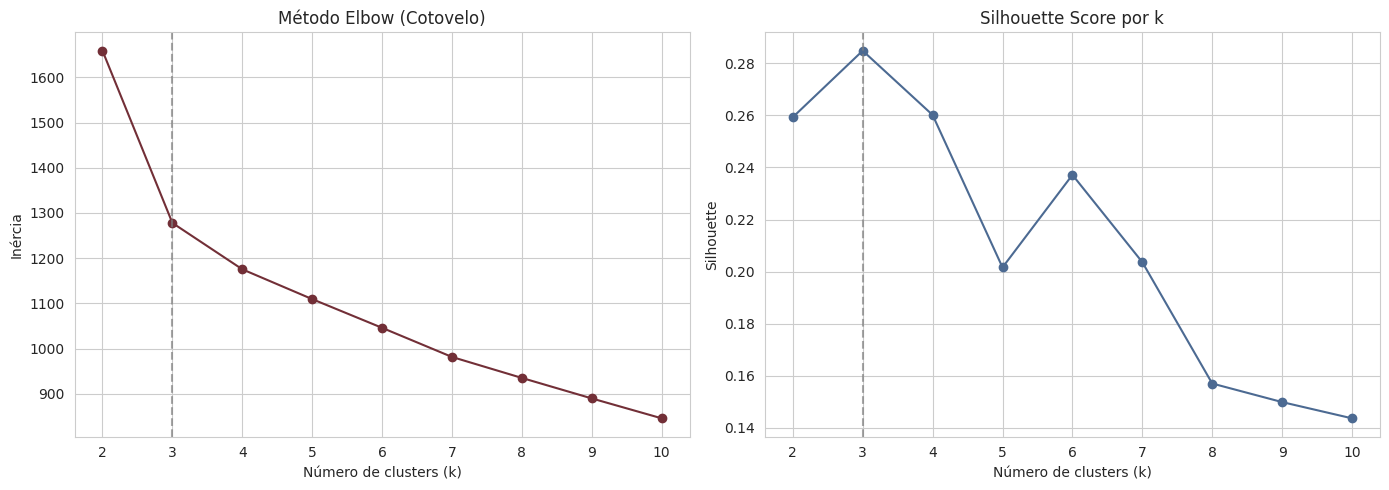

k com maior Silhouette: 3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Elbow ---
axes[0].plot(list(K_range), inercias, marker="o", color="#722F37")
axes[0].set_title("Método Elbow (Cotovelo)")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inércia")
axes[0].axvline(3, color="gray", linestyle="--", alpha=0.7)

# --- Silhouette ---
axes[1].plot(list(K_range), silhuetas, marker="o", color="#4C6A92")
axes[1].set_title("Silhouette Score por k")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette")
axes[1].axvline(3, color="gray", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig("imagens/elbow_silhouette.png", dpi=110)
plt.show()

melhor_k = int(resultado_k.loc[resultado_k["Silhouette"].idxmax(), "k"])
print("k com maior Silhouette:", melhor_k)

**Interpretação:**

- **Elbow:** a inércia cai ~381 pontos de k=2 para k=3, mas só ~102 de k=3 para k=4 e ~66 de k=4 para k=5.
  A queda forte termina em **k=3** — é o cotovelo.
- **Silhouette:** o maior valor é em **k=3 (≈ 0,285)**, acima de k=2 (≈ 0,259) e de todos os outros.
- As duas métricas apontam para o mesmo número, então escolhemos **k = 3**.

**Ressalva honesta:** 0,285 é um valor *moderado*, não "alto". Isso significa que os grupos existem mas
têm alguma sobreposição nas bordas (isso aparece nos gráficos da próxima seção). Para dados reais com 13
dimensões, isso é normal.

## e) Análise dos grupos e das características dos vinhos (3,5 pontos)

Ajustamos o modelo final com k=3 e olhamos a **média de cada característica em cada grupo**.

Um detalhe técnico: o número do grupo que o K-means devolve (0, 1, 2) é arbitrário. Para os rótulos
ficarem **estáveis**, renomeamos os grupos em ordem crescente de teor alcoólico: Grupo 0 = menos
alcoólico, Grupo 2 = mais alcoólico.

In [8]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_bruto = kmeans_final.fit_predict(X)

# Renomeia os grupos por ordem de teor alcoólico médio (0 = menor, 2 = maior).
ordem = df.assign(c=cluster_bruto).groupby("c")["Alcool"].mean().sort_values().index
mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
df["Cluster"] = pd.Series(cluster_bruto).map(mapa)

# Perfil médio de cada grupo (valores nas unidades originais, não padronizadas).
perfil = df.groupby("Cluster")[list(features.columns)].mean().round(2)
perfil.T    # transposto: cada linha é uma característica, cada coluna é um grupo

Cluster,0,1,2
Alcool,12.25,13.13,13.68
Acido_Malico,1.90,3.31,2.00
Cinzas,2.23,2.42,2.47
Alcalinidade_Cinzas,20.06,21.24,17.46
Magnesio,92.74,98.67,107.97
Fenois_Totais,2.25,1.68,2.85
Flavonoides,2.05,0.82,3.00
Fenois_Nao_Flavonoides,0.36,0.45,0.29
Proantocianinas,1.62,1.15,1.92
Intensidade_Cor,2.97,7.23,5.45


In [9]:
print("Vinhos por grupo:")
print(df["Cluster"].value_counts().sort_index())

# Respostas diretas às perguntas do enunciado, calculadas automaticamente:
print("\nTeor alcoólico médio por grupo (%):")
print(df.groupby("Cluster")["Alcool"].mean().round(2))

print("\nÁcido málico médio por grupo (g/L) — acidez:")
print(df.groupby("Cluster")["Acido_Malico"].mean().round(2))

print("\n-> Grupo com maior teor alcoólico:", df.groupby("Cluster")["Alcool"].mean().idxmax())
print("-> Grupo com vinhos mais ácidos   :", df.groupby("Cluster")["Acido_Malico"].mean().idxmax())
print("-> Grupo com mais cinzas          :", df.groupby("Cluster")["Cinzas"].mean().idxmax())
print("-> Grupo com menos cinzas         :", df.groupby("Cluster")["Cinzas"].mean().idxmin())

Vinhos por grupo:
Cluster
0    65
1    51
2    62
Name: count, dtype: int64

Teor alcoólico médio por grupo (%):
Cluster
0    12.25
1    13.13
2    13.68
Name: Alcool, dtype: float64

Ácido málico médio por grupo (g/L) — acidez:
Cluster
0    1.90
1    3.31
2    2.00
Name: Acido_Malico, dtype: float64

-> Grupo com maior teor alcoólico: 2
-> Grupo com vinhos mais ácidos   : 1
-> Grupo com mais cinzas          : 2
-> Grupo com menos cinzas         : 0


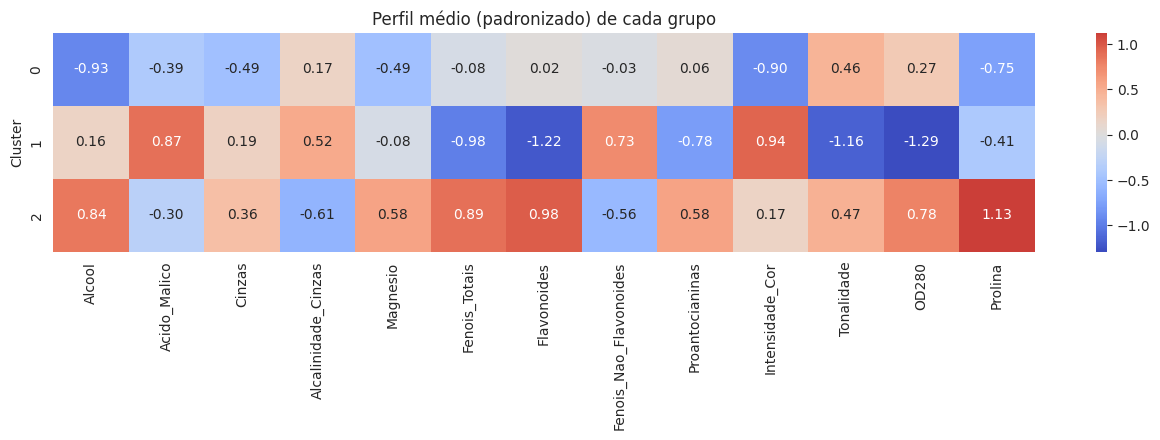

In [10]:
# Heatmap: perfil médio PADRONIZADO. Valores > 0 = acima da média geral; < 0 = abaixo.
# É a melhor forma de enxergar o que diferencia um grupo do outro de uma só vez.
perfil_padr = pd.DataFrame(X, columns=features.columns)
perfil_padr["Cluster"] = df["Cluster"].values
perfil_padr = perfil_padr.groupby("Cluster").mean()

plt.figure(figsize=(13, 4.5))
sns.heatmap(perfil_padr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil médio (padronizado) de cada grupo")
plt.tight_layout()
plt.savefig("imagens/heatmap_clusters.png", dpi=110)
plt.show()

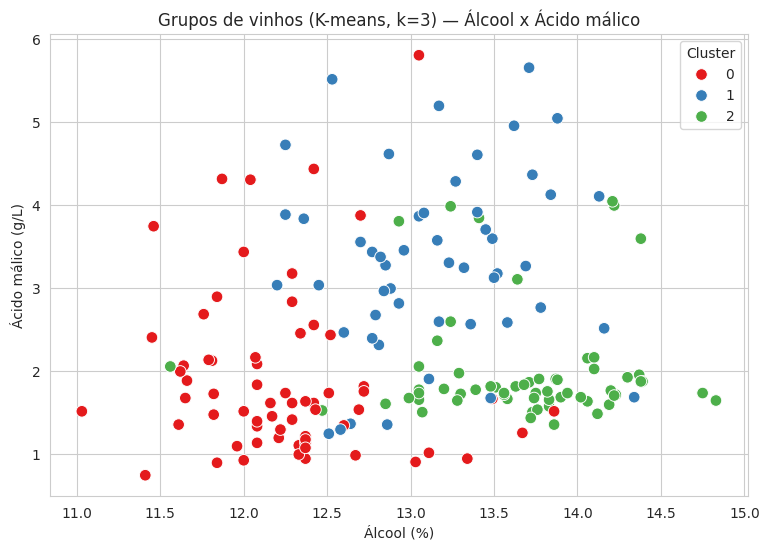

In [11]:
# Dispersão em 2 variáveis (as duas do enunciado: álcool e acidez).
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Alcool", y="Acido_Malico", hue="Cluster", palette="Set1", s=70)
plt.title("Grupos de vinhos (K-means, k=3) — Álcool x Ácido málico")
plt.xlabel("Álcool (%)"); plt.ylabel("Ácido málico (g/L)")
plt.savefig("imagens/clusters_scatter.png", dpi=110)
plt.show()

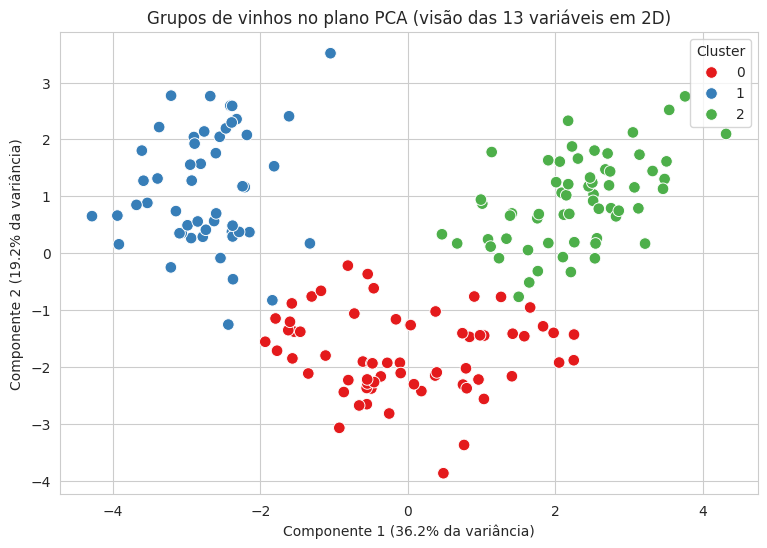

In [12]:
# PCA: o K-means usou 13 variáveis, mas só enxergamos 2 dimensões num gráfico.
# O PCA "comprime" as 13 em 2 eixos que preservam o máximo de informação, só para visualizar.
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df["Cluster"], palette="Set1", s=70)
plt.title("Grupos de vinhos no plano PCA (visão das 13 variáveis em 2D)")
plt.xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)")
plt.ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)")
plt.savefig("imagens/clusters_pca.png", dpi=110)
plt.show()

**Por que dois gráficos de dispersão?** No gráfico Álcool × Ácido málico os grupos se misturam bastante,
porque o K-means decidiu usando as **13 variáveis**, e não só essas duas. No gráfico PCA, que resume as 13
variáveis, os três grupos aparecem bem mais separados. Isso explica o Silhouette moderado e mostra que
a separação real depende de várias variáveis juntas.

### Perfil de cada grupo

| Grupo | Álcool | Ácido málico | Cinzas | Outras características marcantes |
|---|---|---|---|---|
| **0** (65 vinhos) | **menor** (12,25%) | baixo (1,90) | **menos** cinzas (2,23) | cor **clara** (intensidade 2,97), prolina baixa (510), flavonoides médios (2,05) |
| **1** (51 vinhos) | médio (13,13%) | **maior** (3,31) → **vinhos mais ácidos** | cinzas altas (2,42) | **cor mais intensa** (7,23), **menor** tonalidade (0,69), **menor** flavonoides (0,82), menor OD280 (1,70) |
| **2** (62 vinhos) | **maior** (13,68%) | baixo (2,00) | **mais** cinzas (2,47) | **prolina muito alta** (1100), flavonoides e fenóis **altos** (3,00 e 2,85), OD280 alto (3,16), menor alcalinidade das cinzas (17,5) |

**Resumo em uma frase por grupo (formato pedido no enunciado):**
- **Grupo 0:** vinhos mais leves — menor teor alcoólico, pouca cinza, cor clara e baixa concentração de prolina.
- **Grupo 1:** vinhos mais ácidos — maior ácido málico, cor muito intensa, poucos flavonoides e tonalidade mais baixa.
- **Grupo 2:** vinhos mais encorpados — maior teor alcoólico, mais cinzas, prolina muito alta e muitos fenóis/flavonoides.

**Respondendo às perguntas do enunciado:**
- *Qual o teor alcoólico dos vinhos de cada grupo?* 12,25% (G0), 13,13% (G1) e 13,68% (G2).
- *Qual o grupo com vinhos mais ácidos?* O **Grupo 1** (ácido málico médio de 3,31 g/L).

### Validação (opcional): comparando com as cultivares reais

O K-means nunca viu a coluna `Classe`. Agora a usamos **apenas para conferir** se os grupos encontrados
batem com as três cultivares de uva.

In [13]:
# Tabela cruzada: linhas = cultivar real, colunas = grupo encontrado pelo K-means.
comparacao = pd.crosstab(df["Classe"], df["Cluster"])
display(comparacao)

# Acerto: para cada cultivar, pega o grupo dominante e soma quantos vinhos "caíram" nele.
acertos = comparacao.max(axis=1).sum()
print(f"Vinhos no grupo dominante da sua cultivar: {acertos} de {len(df)} ({acertos/len(df)*100:.1f}%)")

Cluster,0,1,2
Classe,,,
0,0,0,59
1,65,3,3
2,0,48,0


Vinhos no grupo dominante da sua cultivar: 172 de 178 (96.6%)


**Comentário:** quase todos os vinhos de cada cultivar caíram no mesmo grupo (~96,6% de coincidência).
Ou seja, o K-means, sem receber rótulo nenhum, **redescobriu** a estrutura real dos dados — as medidas
químicas realmente carregam informação suficiente para diferenciar os tipos de vinho.

## Experimento extra: impacto da escolha das features

Para entender como as variáveis influenciam o agrupamento, repetimos o K-means (k=3) com
diferentes conjuntos de features. Usamos duas métricas: o Silhouette (separação entre os
grupos) e o ARI (concordância com as cultivares reais, usadas apenas para avaliação).

In [14]:
from sklearn.metrics import adjusted_rand_score

def testar_features(colunas, k=3, padronizar=True):
    """Roda o K-means só com as colunas escolhidas e devolve as métricas."""
    X_t = df[colunas].values
    if padronizar:
        X_t = StandardScaler().fit_transform(X_t)   # coloca todas na mesma escala
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = km.fit_predict(X_t)
    return {
        "n_features": len(colunas),
        # Silhouette: quão BEM SEPARADOS ficaram os grupos (quanto maior, melhor)
        "silhouette": round(silhouette_score(X_t, rotulos), 3),
        # ARI: quanto os grupos COINCIDEM com as cultivares reais (1 = idêntico, 0 = aleatório)
        "ARI (vs. cultivar real)": round(adjusted_rand_score(df["Classe"], rotulos), 3),
        "tamanhos": sorted(pd.Series(rotulos).value_counts().tolist()),
    }

todas = list(features.columns)
experimentos = {
    "1. Todas as 13 (base)":              testar_features(todas),
    "2. Todas, SEM padronizar":           testar_features(todas, padronizar=False),
    "3. Só Álcool + Ácido málico":        testar_features(["Alcool", "Acido_Malico"]),
    "4. Flavonoides + Cor + Prolina":     testar_features(["Flavonoides", "Intensidade_Cor", "Prolina"]),
    "5. Sem Prolina":                     testar_features([c for c in todas if c != "Prolina"]),
    "6. Só Cinzas + Magnésio + Alcalin.": testar_features(["Cinzas", "Magnesio", "Alcalinidade_Cinzas"]),
}
pd.DataFrame(experimentos).T

,n_features,silhouette,ARI (vs. cultivar real),tamanhos
1. Todas as 13 (base),13,0.285,0.897,"[51, 62, 65]"
"2. Todas, SEM padronizar",13,0.571,0.371,"[47, 62, 69]"
3. Só Álcool + Ácido málico,2,0.484,0.444,"[49, 63, 66]"
4. Flavonoides + Cor + Prolina,3,0.478,0.829,"[48, 57, 73]"
5. Sem Prolina,12,0.259,0.799,"[50, 63, 65]"
6. Só Cinzas + Magnésio + Alcalin.,3,0.292,0.299,"[33, 66, 79]"


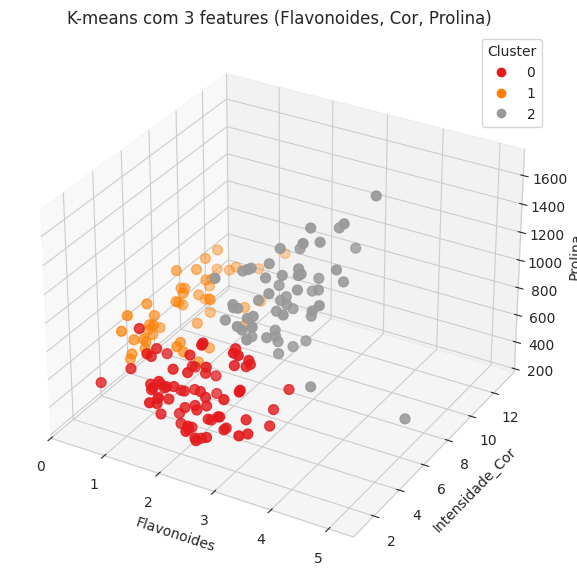

In [15]:
cols = ["Flavonoides", "Intensidade_Cor", "Prolina"]
X3 = StandardScaler().fit_transform(df[cols])                       # padroniza as 3
rot3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X3)  # agrupa só com as 3

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")                          # cria o eixo 3D
sc = ax.scatter(df[cols[0]], df[cols[1]], df[cols[2]], c=rot3, cmap="Set1", s=50)
ax.set_xlabel(cols[0]); ax.set_ylabel(cols[1]); ax.set_zlabel(cols[2])
ax.set_title("K-means com 3 features (Flavonoides, Cor, Prolina)")
ax.legend(*sc.legend_elements(), title="Cluster")
plt.show()



**TESTANDO FEATURE:**
“Com apenas Flavonoides, Intensidade de Cor e Prolina, o ARI foi 0,829 e o Silhouette 0,478, indicando que poucas variáveis bem escolhidas preservam quase toda a estrutura dos dados, embora a versão com 13 variáveis ainda tenha a maior concordância com as cultivares (ARI 0,897).”

## Conclusão

Padronizamos as 13 variáveis (essencial, pois o K-means usa distância), testamos k de 2 a 10 e
**k = 3** foi o melhor tanto no Elbow (fim da queda forte da inércia) quanto no Silhouette (≈ 0,285, o maior).
Os três grupos têm perfis químicos distintos: um **leve** (menos álcool, cor clara), um **ácido** (mais
ácido málico, cor intensa) e um **encorpado** (mais álcool, prolina e fenóis altos). O agrupamento coincide
com as cultivares reais em cerca de 96,6% dos vinhos, mesmo sem usar esse rótulo no treinamento.

**Limitações:** o Silhouette é moderado (grupos se sobrepõem nas bordas) e o K-means assume grupos mais ou
menos esféricos e de tamanho parecido.

---
**Entrega:** Gustavo Lino — RM 574157 | Lucas Lopes Arias — RM 570875